In [1]:
print("Python is working!")

Python is working!


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import mysql.connector

print("All libraries loaded successfully!")

All libraries loaded successfully!


In [3]:
%pip install mysql-connector-python

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [5]:
import mysql.connector
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from getpass import getpass

sns.set_theme(style="whitegrid")

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.2f}".format)

print("Libraries loaded successfully.")

Libraries loaded successfully.


In [8]:
import mysql.connector
from getpass import getpass

password = getpass("Enter your MySQL password: ")

connection = mysql.connector.connect(
    host="127.0.0.1",
    port="3306",
    user="root",
    password=password,
    database="customer_churn",
    use_pure=True
)

print("Connected successfully to telecom_db!")

Enter your MySQL password:  ········


Connected successfully to telecom_db!


In [9]:
cursor = connection.cursor()

cursor.execute("SELECT DATABASE();")
print("Database:", cursor.fetchone()[0])

cursor.execute("SHOW TABLES;")

for table in cursor.fetchall():
    print(table[0])

Database: customer_churn
telecom_customer_churn
telecom_customer_churn_staging
telecom_data_dictionary
telecom_zipcode_population


In [10]:
query = """
SELECT *
FROM telecom_customer_churn;
"""

df = pd.read_sql(query, connection)

print("Rows:", len(df))
print("Columns:", len(df.columns))

display(df.head())

C:\Users\mahzu\AppData\Local\Temp\ipykernel_5760\2204630084.py:6: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(query, connection)


Rows: 7043
Columns: 38


,Customer ID,Gender,Age,Married,Number of Dependents,City,Zip Code,Latitude,Longitude,Number of Referrals,Tenure in Months,Offer,Phone Service,Avg Monthly Long Distance Charges,Multiple Lines,Internet Service,Internet Type,Avg Monthly GB Download,Online Security,Online Backup,Device Protection Plan,Premium Tech Support,Streaming TV,Streaming Movies,Streaming Music,Unlimited Data,Contract,Paperless Billing,Payment Method,Monthly Charge,Total Charges,Total Refunds,Total Extra Data Charges,Total Long Distance Charges,Total Revenue,Customer Status,Churn Category,Churn Reason
0,0002-ORFBO,Female,37,Yes,0,Frazier Park,93225,34.83,-119.00,2,9,None,Yes,42.39,No,Yes,Cable,16.00,No,Yes,No,Yes,Yes,No,No,Yes,One Year,Yes,Credit Card,65.60,593.30,0.00,0.00,381.51,974.81,Stayed,,
1,0003-MKNFE,Male,46,No,0,Glendale,91206,34.16,-118.20,0,9,None,Yes,10.69,Yes,Yes,Cable,10.00,No,No,No,No,No,Yes,Yes,No,Month-to-Month,No,Credit Card,-4.00,542.40,38.33,10.00,96.21,610.28,Stayed,,
2,0004-TLHLJ,Male,50,No,0,Costa Mesa,92627,33.65,-117.92,0,4,Offer E,Yes,33.65,No,Yes,Fiber Optic,30.00,No,No,Yes,No,No,No,No,Yes,Month-to-Month,Yes,Bank Withdrawal,73.90,280.85,0.00,0.00,134.60,415.45,Churned,Competitor,Competitor had better devices
3,0011-IGKFF,Male,78,Yes,0,Martinez,94553,38.01,-122.12,1,13,Offer D,Yes,27.82,No,Yes,Fiber Optic,4.00,No,Yes,Yes,No,Yes,Yes,No,Yes,Month-to-Month,Yes,Bank Withdrawal,98.00,"1,237.85",0.00,0.00,361.66,"1,599.51",Churned,Dissatisfaction,Product dissatisfaction
4,0013-EXCHZ,Female,75,Yes,0,Camarillo,93010,34.23,-119.08,3,3,None,Yes,7.38,No,Yes,Fiber Optic,11.00,No,No,No,Yes,Yes,No,No,Yes,Month-to-Month,Yes,Credit Card,83.90,267.40,0.00,0.00,22.14,289.54,Churned,Dissatisfaction,Network reliability


# How many customers joined the company?

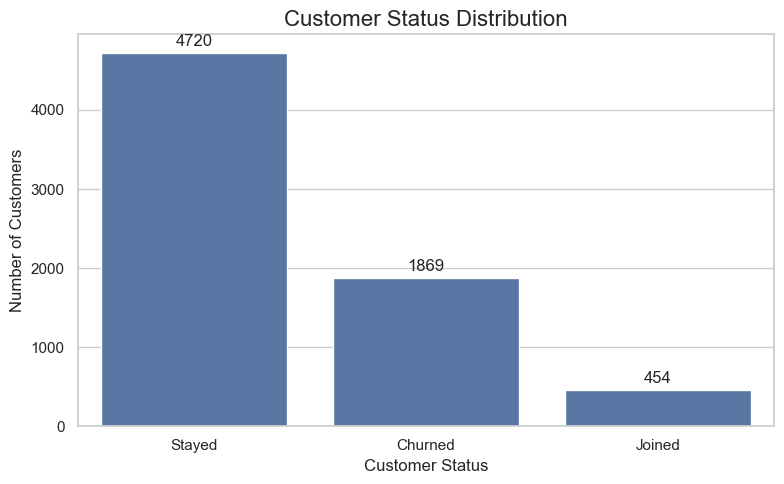

In [11]:
#Customer Status
status = (
    df["Customer Status"]
    .value_counts()
    .reindex(["Stayed", "Churned", "Joined"])
)

fig, ax = plt.subplots(figsize=(8, 5))

sns.barplot(
    x=status.index,
    y=status.values,
    ax=ax
)

ax.set_title("Customer Status Distribution", fontsize=16)
ax.set_xlabel("Customer Status")
ax.set_ylabel("Number of Customers")

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3)

plt.tight_layout()
plt.show()

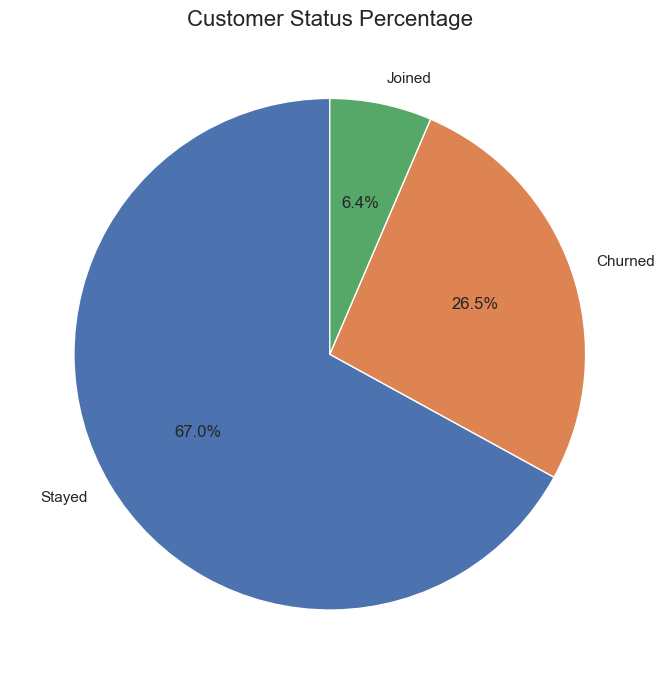

In [12]:
#1B — Percentage
status_pct = (
    df["Customer Status"]
    .value_counts()
    .reindex(["Stayed", "Churned", "Joined"])
)

fig, ax = plt.subplots(figsize=(7, 7))

ax.pie(
    status_pct.values,
    labels=status_pct.index,
    autopct="%1.1f%%",
    startangle=90
)

ax.set_title("Customer Status Percentage", fontsize=16)

plt.tight_layout()
plt.show()

# What is the customer profile for churned, joined and stayed customers?

In [13]:
#Customer Profile
profile = (
    df.groupby("Customer Status")
      .agg(
          total_customers=("Customer ID", "count"),
          avg_age=("Age", "mean"),
          avg_tenure_months=("Tenure in Months", "mean"),
          avg_monthly_charge=("Monthly Charge", "mean"),
          avg_total_revenue=("Total Revenue", "mean")
      )
      .round(2)
)

profile = profile.reindex(["Stayed", "Churned", "Joined"])

display(profile)

,total_customers,avg_age,avg_tenure_months,avg_monthly_charge,avg_total_revenue
Customer Status,,,,,
Stayed,4720,45.58,41.04,61.74,"3,735.68"
Churned,1869,49.74,17.98,73.35,"1,971.35"
Joined,454,42.87,1.72,42.78,119.56


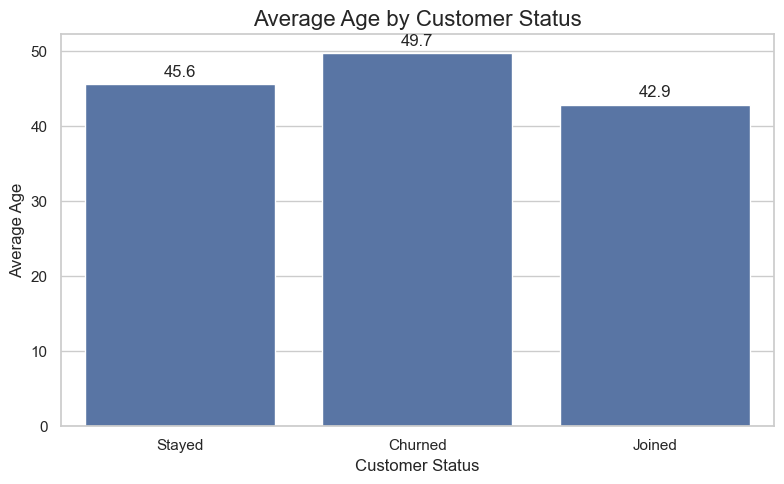

In [14]:
#Age
fig, ax = plt.subplots(figsize=(8, 5))

sns.barplot(
    data=profile.reset_index(),
    x="Customer Status",
    y="avg_age",
    ax=ax
)

ax.set_title("Average Age by Customer Status", fontsize=16)
ax.set_xlabel("Customer Status")
ax.set_ylabel("Average Age")

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f", padding=3)

plt.tight_layout()
plt.show()

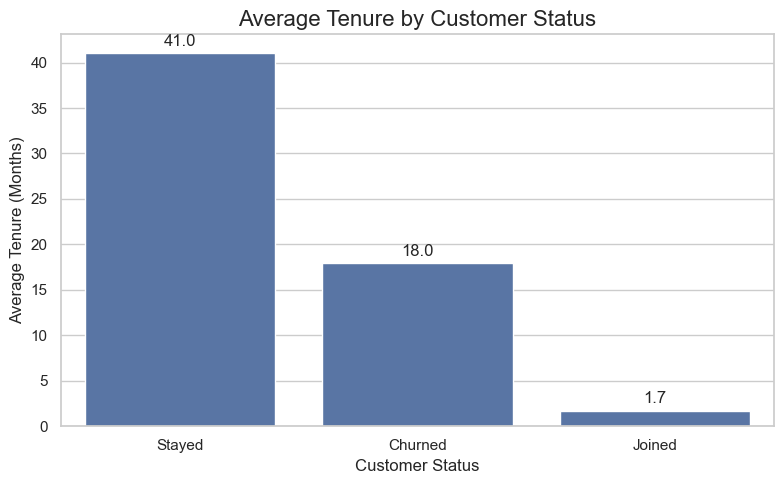

In [15]:
#Tenure
fig, ax = plt.subplots(figsize=(8, 5))

sns.barplot(
    data=profile.reset_index(),
    x="Customer Status",
    y="avg_tenure_months",
    ax=ax
)

ax.set_title("Average Tenure by Customer Status", fontsize=16)
ax.set_xlabel("Customer Status")
ax.set_ylabel("Average Tenure (Months)")

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f", padding=3)

plt.tight_layout()
plt.show()

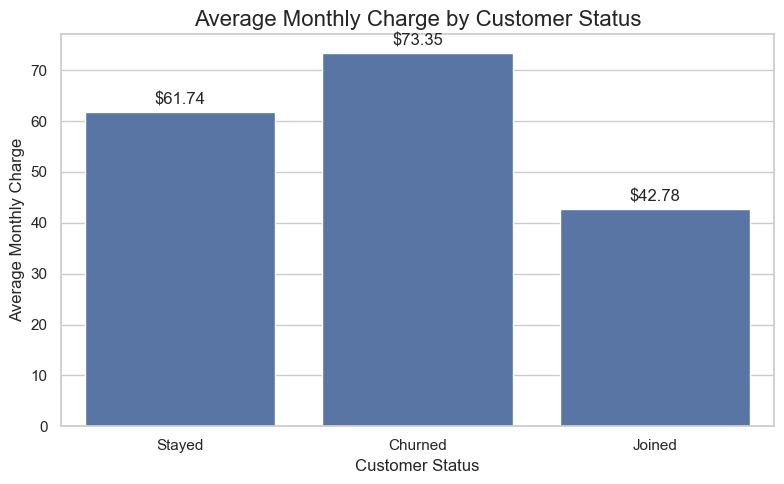

In [16]:
#Monthly Change
fig, ax = plt.subplots(figsize=(8, 5))

sns.barplot(
    data=profile.reset_index(),
    x="Customer Status",
    y="avg_monthly_charge",
    ax=ax
)

ax.set_title("Average Monthly Charge by Customer Status", fontsize=16)
ax.set_xlabel("Customer Status")
ax.set_ylabel("Average Monthly Charge")

for container in ax.containers:
    ax.bar_label(container, fmt="$%.2f", padding=3)

plt.tight_layout()
plt.show()

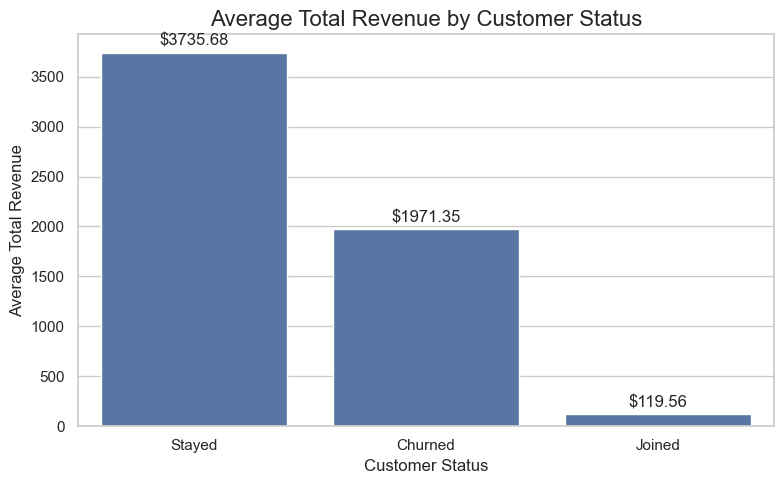

In [17]:
#total Revenue
fig, ax = plt.subplots(figsize=(8, 5))

sns.barplot(
    data=profile.reset_index(),
    x="Customer Status",
    y="avg_total_revenue",
    ax=ax
)

ax.set_title("Average Total Revenue by Customer Status", fontsize=16)
ax.set_xlabel("Customer Status")
ax.set_ylabel("Average Total Revenue")

for container in ax.containers:
    ax.bar_label(container, fmt="$%.2f", padding=3)

plt.tight_layout()
plt.show()

# What seem to be the key drivers of customer churn?

In [19]:
churn_reasons = (
    df[
        (df["Customer Status"] == "Churned") &
        (df["Churn Reason"].notna()) &
        (df["Churn Reason"].str.strip() != "")
    ]
    .groupby(["Churn Category", "Churn Reason"])
    .size()
    .reset_index(name="customer_count")
    .sort_values("customer_count", ascending=False)
)

display(churn_reasons.head(20))

,Churn Category,Churn Reason,customer_count
2,Competitor,Competitor had better devices,313
3,Competitor,Competitor made better offer,311
1,Attitude,Attitude of support person,220
14,Other,Don't know,130
5,Competitor,Competitor offered more data,117
4,Competitor,Competitor offered higher download speeds,100
0,Attitude,Attitude of service provider,94
19,Price,Price too high,78
11,Dissatisfaction,Product dissatisfaction,77
8,Dissatisfaction,Network reliability,72


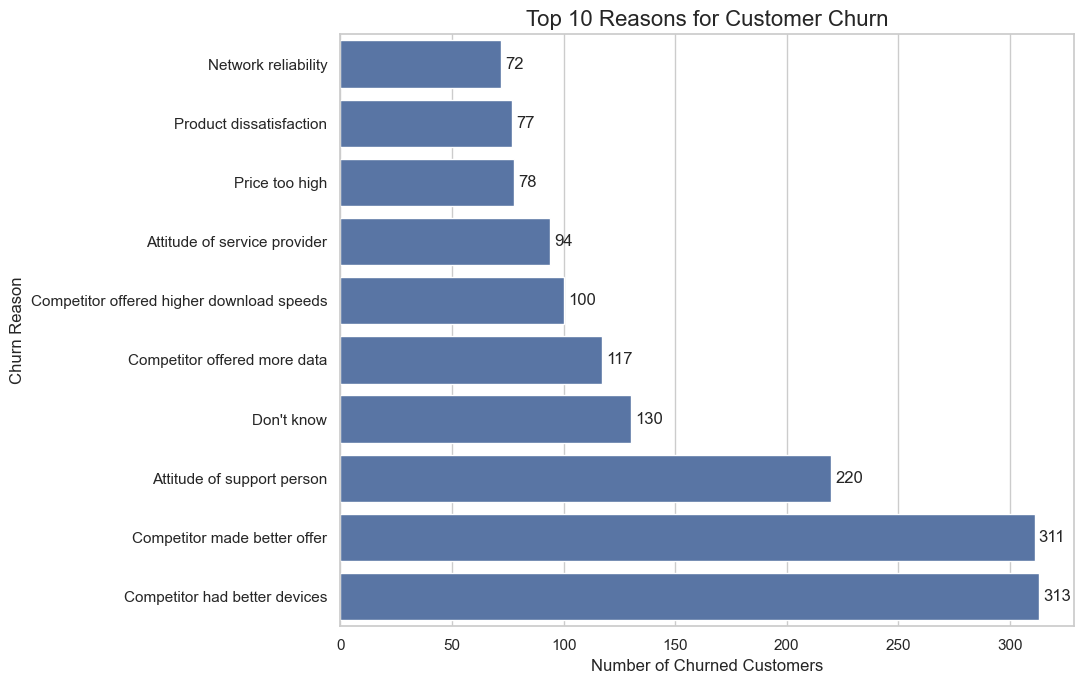

In [20]:
#Top 10 churn reasons
top_reasons = churn_reasons.head(10).sort_values(
    "customer_count",
    ascending=True
)

fig, ax = plt.subplots(figsize=(11, 7))

sns.barplot(
    data=top_reasons,
    x="customer_count",
    y="Churn Reason",
    ax=ax
)

ax.set_title("Top 10 Reasons for Customer Churn", fontsize=16)
ax.set_xlabel("Number of Churned Customers")
ax.set_ylabel("Churn Reason")

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3)

plt.tight_layout()
plt.show()

In [23]:
df["Is_Churned"] = (
    df["Customer Status"] == "Churned"
).astype(int)

print(df[["Customer Status", "Is_Churned"]].head())

  Customer Status  Is_Churned
0          Stayed           0
1          Stayed           0
2         Churned           1
3         Churned           1
4         Churned           1


In [24]:
#Internet Types
internet = (
    df.groupby("Internet Type")
      .agg(
          total_customers=("Customer ID", "count"),
          churned_customers=("Is_Churned", "sum")
      )
)

internet["churn_rate_percent"] = (
    internet["churned_customers"]
    / internet["total_customers"] * 100
)

internet = internet.sort_values(
    "churn_rate_percent",
    ascending=False
)

display(internet.round(2))

,total_customers,churned_customers,churn_rate_percent
Internet Type,,,
Fiber Optic,3035,1236,40.72
Cable,830,213,25.66
DSL,1652,307,18.58
,1526,113,7.40


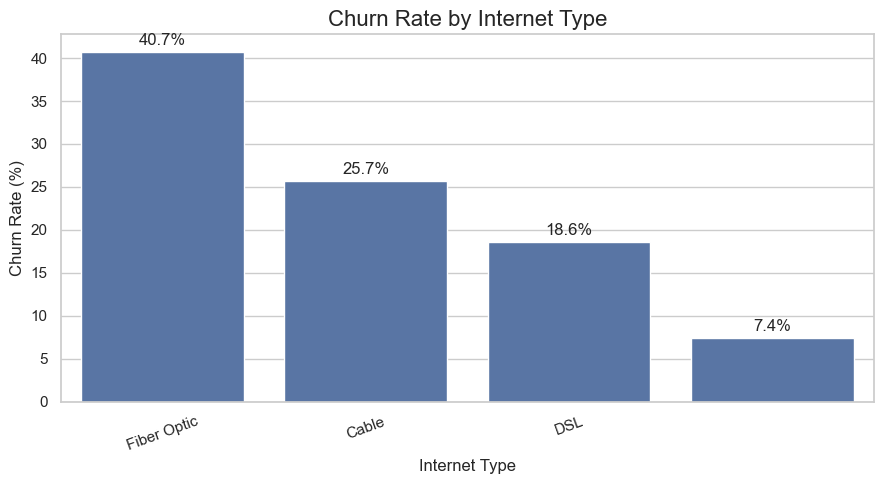

In [25]:
fig, ax = plt.subplots(figsize=(9, 5))

sns.barplot(
    data=internet.reset_index(),
    x="Internet Type",
    y="churn_rate_percent",
    ax=ax
)

ax.set_title("Churn Rate by Internet Type", fontsize=16)
ax.set_xlabel("Internet Type")
ax.set_ylabel("Churn Rate (%)")

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)

plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [26]:
#Payment Method
payment = (
    df.groupby("Payment Method")
      .agg(
          total_customers=("Customer ID", "count"),
          churned_customers=("Is_Churned", "sum")
      )
)

payment["churn_rate_percent"] = (
    payment["churned_customers"]
    / payment["total_customers"] * 100
)

payment = payment.sort_values(
    "churn_rate_percent",
    ascending=False
)

display(payment.round(2))

,total_customers,churned_customers,churn_rate_percent
Payment Method,,,
Mailed Check,385,142,36.88
Bank Withdrawal,3909,1329,34.00
Credit Card,2749,398,14.48


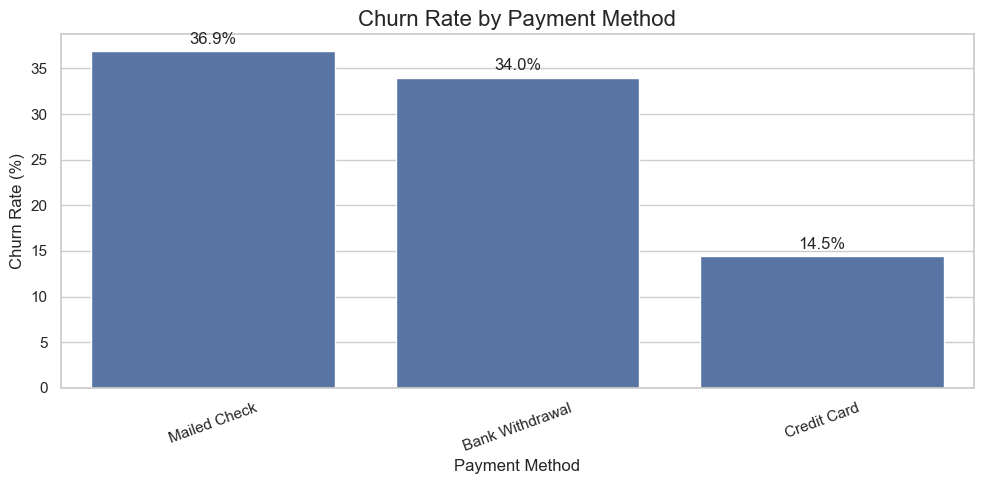

In [27]:
fig, ax = plt.subplots(figsize=(10, 5))

sns.barplot(
    data=payment.reset_index(),
    x="Payment Method",
    y="churn_rate_percent",
    ax=ax
)

ax.set_title("Churn Rate by Payment Method", fontsize=16)
ax.set_xlabel("Payment Method")
ax.set_ylabel("Churn Rate (%)")

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)

plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [28]:
#Support and Online Security
support = (
    df.groupby(
        ["Premium Tech Support", "Online Security"]
    )
    .agg(
        total_customers=("Customer ID", "count"),
        churned_customers=("Is_Churned", "sum")
    )
)

support["churn_rate_percent"] = (
    support["churned_customers"]
    / support["total_customers"] * 100
)

display(
    support.sort_values(
        "churn_rate_percent",
        ascending=False
    ).round(2)
)

,,total_customers,churned_customers,churn_rate_percent
Premium Tech Support,Online Security,,,
No,No,2553,1250,48.96
Yes,No,945,211,22.33
No,Yes,920,196,21.30
Yes,Yes,1099,99,9.01
,,1526,113,7.40


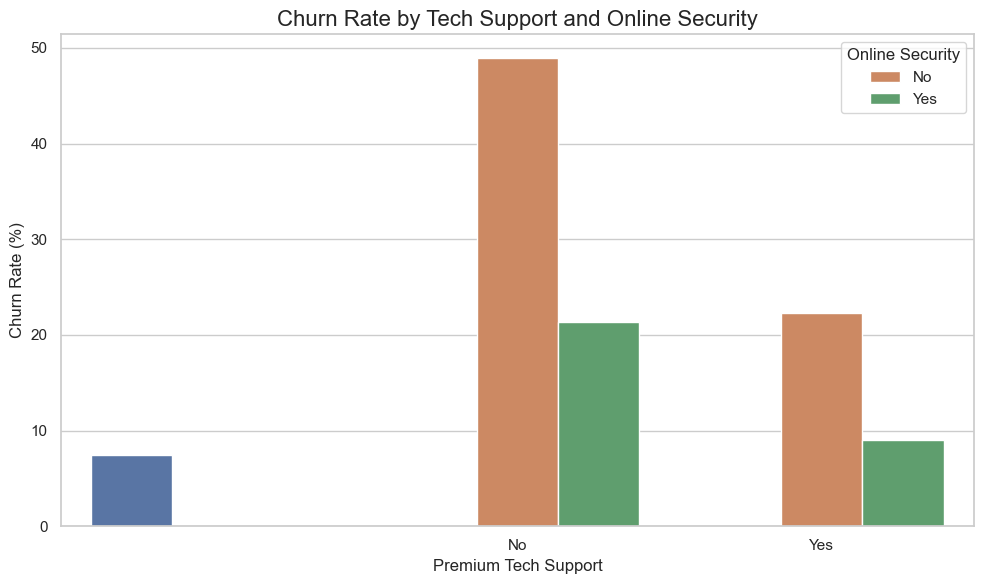

In [29]:
support_plot = support.reset_index()

plt.figure(figsize=(10, 6))

sns.barplot(
    data=support_plot,
    x="Premium Tech Support",
    y="churn_rate_percent",
    hue="Online Security"
)

plt.title(
    "Churn Rate by Tech Support and Online Security",
    fontsize=16
)

plt.xlabel("Premium Tech Support")
plt.ylabel("Churn Rate (%)")

plt.tight_layout()
plt.show()

# Is the company losing high-value customers?

In [30]:
#Average monthly charge by status
value_status = (
    df.groupby("Customer Status")
      .agg(
          total_customers=("Customer ID", "count"),
          avg_monthly_charge=("Monthly Charge", "mean"),
          avg_total_revenue=("Total Revenue", "mean"),
          total_revenue=("Total Revenue", "sum"),
          avg_tenure=("Tenure in Months", "mean")
      )
      .round(2)
      .reindex(["Stayed", "Churned", "Joined"])
)

display(value_status)

,total_customers,avg_monthly_charge,avg_total_revenue,total_revenue,avg_tenure
Customer Status,,,,,
Stayed,4720,61.74,"3,735.68","17,632,392.12",41.04
Churned,1869,73.35,"1,971.35","3,684,459.82",17.98
Joined,454,42.78,119.56,"54,279.75",1.72


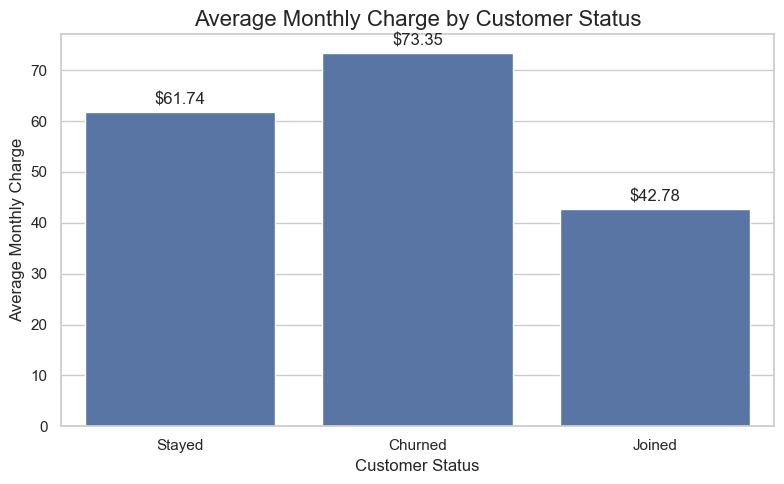

In [31]:
fig, ax = plt.subplots(figsize=(8, 5))

sns.barplot(
    data=value_status.reset_index(),
    x="Customer Status",
    y="avg_monthly_charge",
    ax=ax
)

ax.set_title(
    "Average Monthly Charge by Customer Status",
    fontsize=16
)

ax.set_xlabel("Customer Status")
ax.set_ylabel("Average Monthly Charge")

for container in ax.containers:
    ax.bar_label(container, fmt="$%.2f", padding=3)

plt.tight_layout()
plt.show()

In [32]:
#High Customer Churn
df["Value_Quartile"] = pd.qcut(
    df["Monthly Charge"].rank(method="first"),
    q=4,
    labels=[1, 2, 3, 4]
).astype(int)

df["Value_Segment"] = df["Value_Quartile"].map({
    1: "Lowest 25%",
    2: "Lower-Middle 25%",
    3: "Upper-Middle 25%",
    4: "Highest 25%"
})

In [33]:
value_segments = (
    df.groupby(
        ["Value_Quartile", "Value_Segment"],
        observed=True
    )
    .agg(
        total_customers=("Customer ID", "count"),
        churned_customers=("Is_Churned", "sum"),
        avg_monthly_charge=("Monthly Charge", "mean")
    )
)

value_segments["churn_rate_percent"] = (
    value_segments["churned_customers"]
    / value_segments["total_customers"] * 100
)

display(value_segments.round(2))

,,total_customers,churned_customers,avg_monthly_charge,churn_rate_percent
Value_Quartile,Value_Segment,,,,
1,Lowest 25%,1761,192,19.75,10.90
2,Lower-Middle 25%,1761,427,54.09,24.25
3,Upper-Middle 25%,1760,669,79.82,38.01
4,Highest 25%,1761,581,100.74,32.99


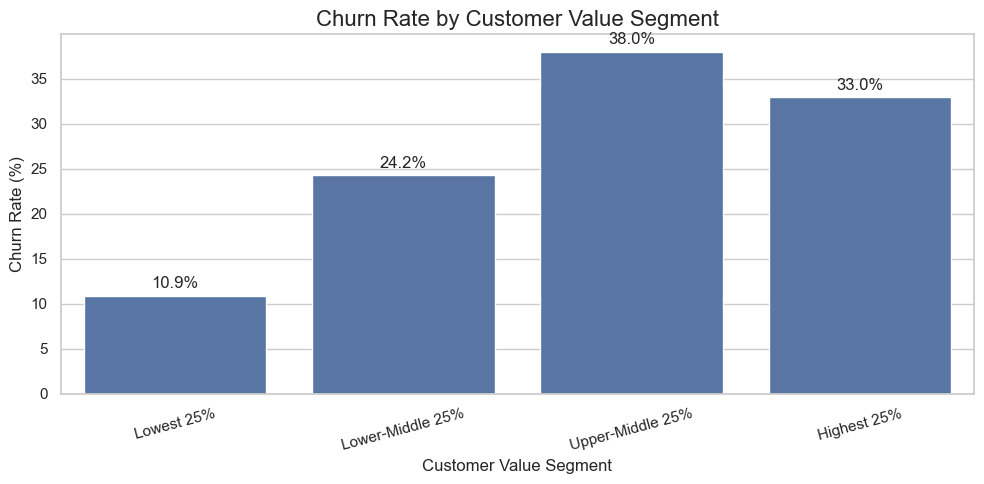

In [34]:
plot_value = value_segments.reset_index()

segment_order = [
    "Lowest 25%",
    "Lower-Middle 25%",
    "Upper-Middle 25%",
    "Highest 25%"
]

fig, ax = plt.subplots(figsize=(10, 5))

sns.barplot(
    data=plot_value,
    x="Value_Segment",
    y="churn_rate_percent",
    order=segment_order,
    ax=ax
)

ax.set_title(
    "Churn Rate by Customer Value Segment",
    fontsize=16
)

ax.set_xlabel("Customer Value Segment")
ax.set_ylabel("Churn Rate (%)")

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [35]:
connection.close()
print("MySQL connection closed.")

MySQL connection closed.
